# Actividad 5: Entrenamiento, Ajuste y Registro de Experimentos con MLflow
**Objetivo:** Preparar y versionar el dataset *Breast Cancer Wisconsin*, entrenar dos algoritmos (Regresión Logística vs. Random Forest) mediante `5-Fold GridSearchCV`, y auditar el registro de parámetros, métricas y artefactos en **MLflow**.

In [1]:
# 1. Instalar dependencias en el entorno de Colab
!pip install -q mlflow scikit-learn pandas numpy matplotlib

import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from mlflow.tracking import MlflowClient
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Crear carpetas del proyecto si no existen en Colab
os.makedirs("datos/datos_ini", exist_ok=True)
os.makedirs("datos/datos_limp", exist_ok=True)
os.makedirs("fuentes", exist_ok=True)

# Agregar 'fuentes' al path para poder importar nuestros módulos .py
sys.path.append(os.path.abspath("fuentes"))
print("Entorno configurado correctamente.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 26.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

In [2]:
%%writefile fuentes/datos_prep.py
import os
import hashlib
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

def cargar_datos_originales(ruta_ini="datos/datos_ini/breast_cancer_raw.csv"):
    os.makedirs(os.path.dirname(ruta_ini), exist_ok=True)
    data = load_breast_cancer()
    df_raw = pd.DataFrame(data.data, columns=data.feature_names)
    df_raw['target'] = data.target
    df_raw.to_csv(ruta_ini, index=False)
    print(f"[DATOS_INI] Guardado en: {ruta_ini} ({df_raw.shape[0]} filas x {df_raw.shape[1]} columnas)")
    return df_raw

def limpiar_y_preparar_datos(df_raw, ruta_limp="datos/datos_limp/breast_cancer_clean.csv"):
    os.makedirs(os.path.dirname(ruta_limp), exist_ok=True)
    df = df_raw.copy().drop_duplicates()
    df = df.fillna(df.median(numeric_only=True))

    X = df.drop('target', axis=1)
    y = df['target']

    scaler = StandardScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

    df_clean = pd.concat([X_scaled, y.reset_index(drop=True)], axis=1)
    df_clean.to_csv(ruta_limp, index=False)

    with open(ruta_limp, "rb") as f:
        data_hash = hashlib.sha256(f.read()).hexdigest()[:12]

    version_tag = f"v1.0_{data_hash}"
    print(f"[DATOS_LIMP] Guardado en: {ruta_limp} | Versión SHA-256: {version_tag}")
    return df_clean, version_tag

Writing fuentes/datos_prep.py


In [9]:
%%writefile fuentes/train.py
import os
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, ConfusionMatrixDisplay
)

TRACKING_URI = "file:./mlruns"
EXPERIMENT_NAME = "Actividad5_Clasificacion_MLOps"

def configurar_mlflow():
    mlflow.set_tracking_uri(TRACKING_URI)
    experiment = mlflow.set_experiment(EXPERIMENT_NAME)
    return experiment

def entrenar_y_registrar(model, param_grid, run_name, X_train, X_test, y_train, y_test, data_version):
    with mlflow.start_run(run_name=run_name) as run:
        grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring='f1', n_jobs=-1)
        grid_search.fit(X_train, y_train)

        best_model = grid_search.best_estimator_
        y_pred = best_model.predict(X_test)
        y_prob = best_model.predict_proba(X_test)[:, 1]

        metrics = {
            "cv_mean_f1": round(grid_search.best_score_, 4),
            "test_accuracy": round(accuracy_score(y_test, y_pred), 4),
            "test_precision": round(precision_score(y_test, y_pred), 4),
            "test_recall": round(recall_score(y_test, y_pred), 4),
            "test_f1_score": round(f1_score(y_test, y_pred), 4),
            "test_roc_auc": round(roc_auc_score(y_test, y_prob), 4)
        }

        mlflow.set_tag("dataset_version", data_version)
        mlflow.set_tag("validation_strategy", "5-Fold GridSearchCV")
        mlflow.log_params(grid_search.best_params_)
        mlflow.log_metrics(metrics)

        os.makedirs("temp_artifacts", exist_ok=True)
        fig, ax = plt.subplots(figsize=(5, 4))
        ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues")
        ax.set_title(f"Matriz de Confusión - {run_name}")
        plot_path = f"temp_artifacts/confusion_matrix_{run_name}.png"
        plt.savefig(plot_path, bbox_inches="tight")
        plt.close(fig)
        mlflow.log_artifact(plot_path, artifact_path="evaluacion_plots")

        # SOLUCIÓN AL ERROR: Especificar serialization_format="cloudpickle"
        mlflow.sklearn.log_model(
            sk_model=best_model,
            artifact_path="model",
            serialization_format="cloudpickle",
            input_example=X_train.iloc[:3].astype("float64")
        )
        print(f"✔ [{run_name}] registrado en MLflow (Run ID: {run.info.run_id})")
        return best_model, grid_search.best_params_, metrics, plot_path

Overwriting fuentes/train.py


In [10]:
from datos_prep import cargar_datos_originales, limpiar_y_preparar_datos

# 1. Cargar datos crudos y limpiarlos
df_raw = cargar_datos_originales()
df_clean, data_version = limpiar_y_preparar_datos(df_raw)

# 2. Mostrar vista previa de los datos limpios y estandarizados
print("\nVista previa de los datos limpios (escalados con StandardScaler):")
display(df_clean.head(3))

# 3. División Train / Test (80% / 20% estratificado)
X = df_clean.drop('target', axis=1)
y = df_clean['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"\nTamaño Train: {X_train.shape[0]} muestras | Tamaño Test: {X_test.shape[0]} muestras")

[DATOS_INI] Guardado en: datos/datos_ini/breast_cancer_raw.csv (569 filas x 31 columnas)
[DATOS_LIMP] Guardado en: datos/datos_limp/breast_cancer_clean.csv | Versión SHA-256: v1.0_7142fb903d2d

Vista previa de los datos limpios (escalados con StandardScaler):


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,...,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015,0
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,...,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190,0
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,...,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391,0



Tamaño Train: 455 muestras | Tamaño Test: 114 muestras


Experimento activo: Actividad5_Clasificacion_MLOps (ID: 227006387724001973)



2026/10/18 18:33:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/18 18:33:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can 

✔ [Logistic_Regression_Tuned] registrado en MLflow (Run ID: ab3e374b5a694c4ba7e5712c9a41bfbb)


2026/10/18 18:34:13 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/18 18:34:13 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can 

✔ [Random_Forest_Tuned] registrado en MLflow (Run ID: 47fb923d046f4cb2a97cf2b5af2043a6)


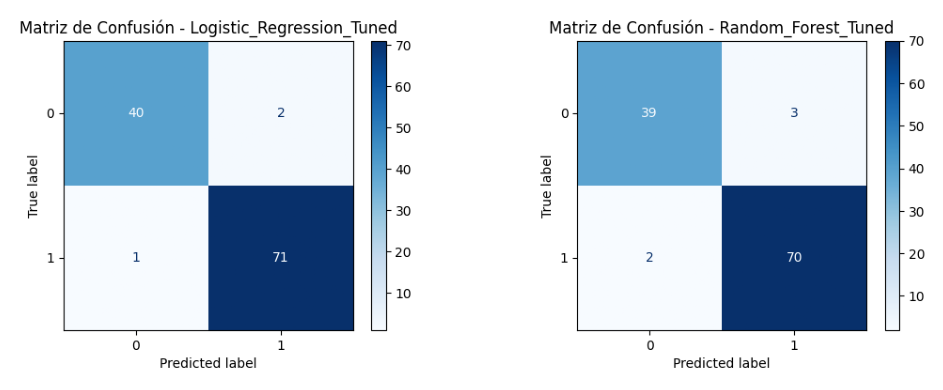

In [11]:
import importlib
import train
importlib.reload(train)
from train import configurar_mlflow, entrenar_y_registrar
import matplotlib.image as mpimg

experiment = configurar_mlflow()
print(f"Experimento activo: {experiment.name} (ID: {experiment.experiment_id})\n")

# --- Modelo 1: Regresión Logística ---
lr_grid = {'C': [0.01, 0.1, 1.0, 10.0], 'penalty': ['l2'], 'solver': ['lbfgs', 'liblinear']}
modelo_lr, params_lr, metricas_lr, plot_lr = entrenar_y_registrar(
    LogisticRegression(max_iter=1000, random_state=42),
    lr_grid, "Logistic_Regression_Tuned", X_train, X_test, y_train, y_test, data_version
)

# --- Modelo 2: Random Forest ---
rf_grid = {'n_estimators': [50, 100, 200], 'max_depth': [None, 5, 10], 'min_samples_split': [2, 5]}
modelo_rf, params_rf, metricas_rf, plot_rf = entrenar_y_registrar(
    RandomForestClassifier(random_state=42),
    rf_grid, "Random_Forest_Tuned", X_train, X_test, y_train, y_test, data_version
)

# Mostrar lado a lado las Matrices de Confusión generadas como artefactos
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(mpimg.imread(plot_lr))
axes[0].axis('off')
axes[1].imshow(mpimg.imread(plot_rf))
axes[1].axis('off')
plt.tight_layout()
plt.show()

In [12]:
# 1. Consultar directamente las corridas exitosas registradas en MLflow
df_runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="attributes.status = 'FINISHED'"
).drop_duplicates(subset=["tags.mlflow.runName"], keep="first")

columnas_comparativas = [
    'tags.mlflow.runName', 'tags.dataset_version',
    'metrics.cv_mean_f1', 'metrics.test_accuracy',
    'metrics.test_precision', 'metrics.test_recall',
    'metrics.test_f1_score', 'metrics.test_roc_auc'
]

print("=== TABLA COMPARATIVA EXTRAÍDA DE MLFLOW ===")
display(df_runs[columnas_comparativas])

# 2. Auditoría de Artefactos con MlflowClient
client = MlflowClient()
print("\n=== VALIDACIÓN DE ARTEFACTOS FÍSICOS EN ./mlruns ===")
for _, row in df_runs.iterrows():
    run_id = row["run_id"]
    r = client.get_run(run_id)
    name = r.data.tags.get("mlflow.runName")
    arts_model = [a.path for a in client.list_artifacts(run_id, "model")]
    arts_plots = [a.path for a in client.list_artifacts(run_id, "evaluacion_plots")]
    print(f"▶ {name} (Run ID: {run_id})")
    print(f"  Parámetros : {r.data.params}")
    print(f"  Artefactos : {arts_model} | {arts_plots}\n")

=== TABLA COMPARATIVA EXTRAÍDA DE MLFLOW ===


,tags.mlflow.runName,tags.dataset_version,metrics.cv_mean_f1,metrics.test_accuracy,metrics.test_precision,metrics.test_recall,metrics.test_f1_score,metrics.test_roc_auc
0,Random_Forest_Tuned,v1.0_7142fb903d2d,0.9684,0.9561,0.9589,0.9722,0.9655,0.9931
1,Logistic_Regression_Tuned,v1.0_7142fb903d2d,0.9845,0.9737,0.9726,0.9861,0.9793,0.9957



=== VALIDACIÓN DE ARTEFACTOS FÍSICOS EN ./mlruns ===
▶ Random_Forest_Tuned (Run ID: 47fb923d046f4cb2a97cf2b5af2043a6)
  Parámetros : {'min_samples_split': '2', 'max_depth': 'None', 'n_estimators': '200'}
  Artefactos : ['model/MLmodel', 'model/conda.yaml', 'model/input_example.json', 'model/model.pkl', 'model/python_env.yaml', 'model/requirements.txt', 'model/serving_input_example.json'] | ['evaluacion_plots/confusion_matrix_Random_Forest_Tuned.png']

▶ Logistic_Regression_Tuned (Run ID: ab3e374b5a694c4ba7e5712c9a41bfbb)
  Parámetros : {'penalty': 'l2', 'C': '0.1', 'solver': 'lbfgs'}
  Artefactos : ['model/MLmodel', 'model/conda.yaml', 'model/input_example.json', 'model/model.pkl', 'model/python_env.yaml', 'model/requirements.txt', 'model/serving_input_example.json'] | ['evaluacion_plots/confusion_matrix_Logistic_Regression_Tuned.png']

